In [7]:
#!/usr/bin/env python3
import numpy as np
from matplotlib import pyplot as plt
import pandas as pd

try:
    import mplhep as hep
    hep.style.use("ATLAS")
except:
    pass


### Get B2TF recast data

In [8]:
b2tf_DF = pd.read_csv('../b2tf_effs_13TeV_new.csv')
b2tf_DF['dm'] = (b2tf_DF['m1']-b2tf_DF['m0']).round(0)
b2tf_DF['ctau'] = (b2tf_DF['tau']*2.99e8).round(0)
b2tf_DF['ctau_full'] = (b2tf_DF['tau']*2.99e8)
b2tf_DF['xsec_fb'] = (b2tf_DF['xsec_pb']*1e3)
b2tf_DF['N_Run2'] = b2tf_DF['eff']*b2tf_DF['xsec_fb']*139.0
b2tf_DF['N_Run2_err'] = b2tf_DF['efferror']*b2tf_DF['xsec_fb']*139.0
# Remove large deltaM, which results in promptly decaying chi1 through the process chi1 -> chi2* + h -> (chi0 + h) + h
# b2tf_DF = b2tf_DF[b2tf_DF['dm'] < 250.0].copy()
print(len(b2tf_DF))



138


In [9]:
# df = b2tf_DF[['ms','m2','m1','m0', 'ctau', 'lambdauv', 'chxx10', 'ychi20', 'ychi21', 'sina', 'xsec_pb', 'eff', 'efferror']].sort_values(by=['eff'], ascending=[False]).copy()
# df.to_csv('../effs_13TeV_new.csv', index=False)

In [10]:
b2tf_DF['ms'].unique(),b2tf_DF['ctau'].unique(),b2tf_DF['dm'].unique()

(array([ 400., 1000.,  500.,  550.,  450.,  600.,  800.]),
 array([20.]),
 array([ 15.,  30.,  60., 100.]))

## Plot Effs

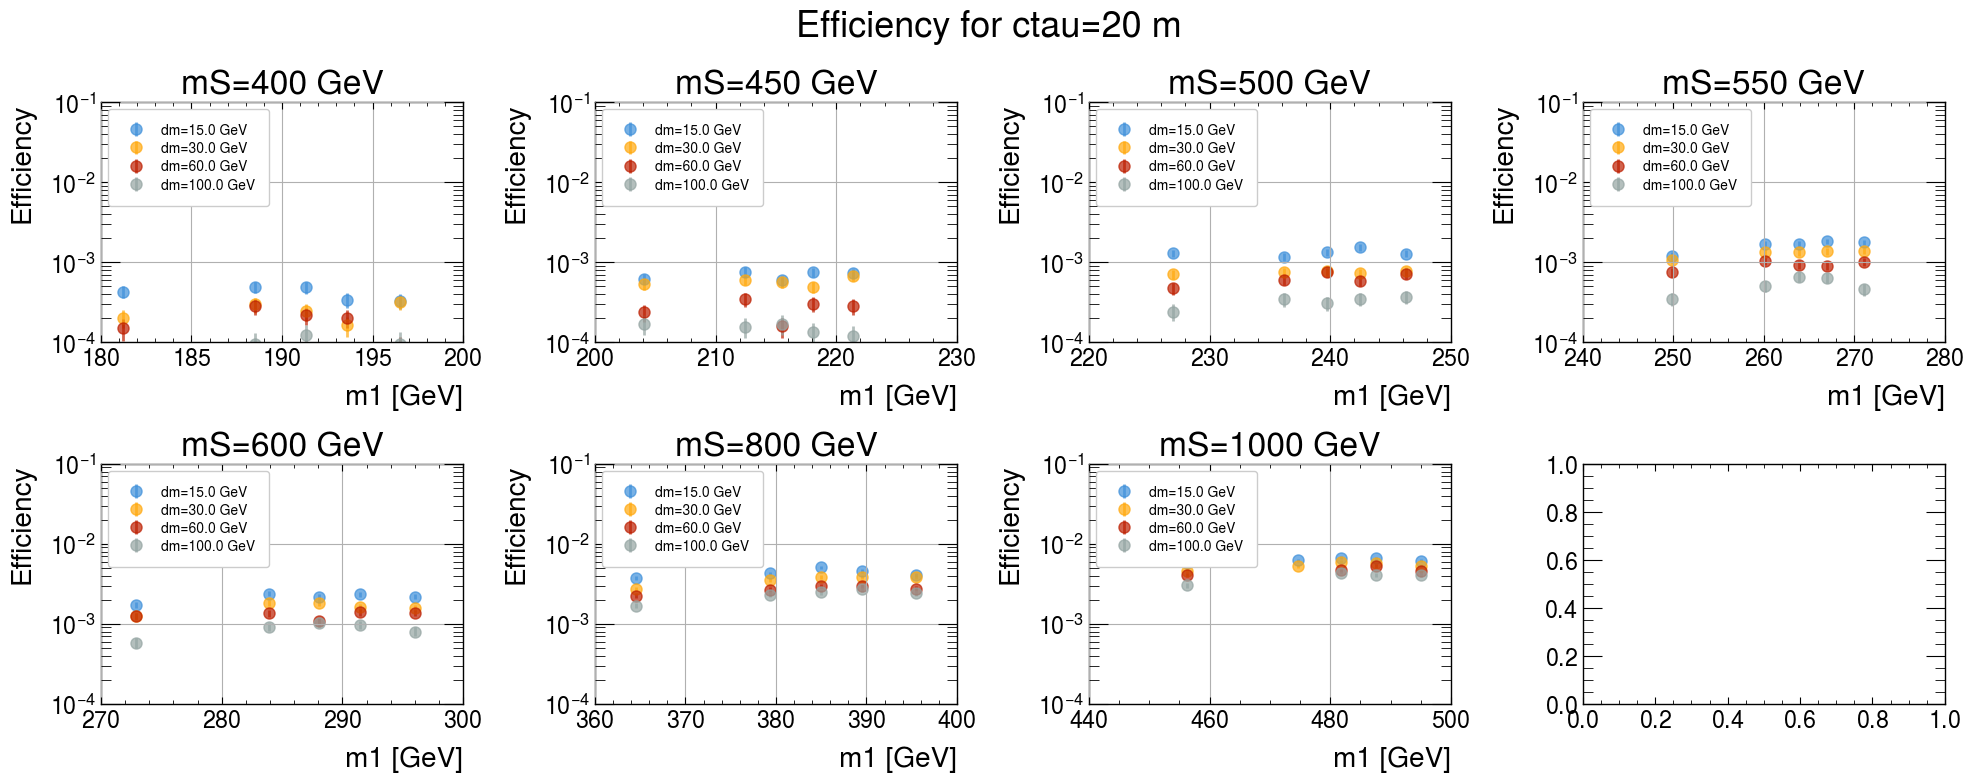

In [11]:
mSValues = sorted(b2tf_DF['ms'].unique())
ncolumns = 4
nrows = len(mSValues) // ncolumns + (len(mSValues) % ncolumns > 0)
ctau = b2tf_DF['ctau'].unique()
fig,axarr = plt.subplots(nrows=nrows, ncols=ncolumns, figsize=(5*ncolumns, 4*nrows))
iax = 0
axes = axarr.flatten() if nrows > 1 else [axarr]
ctau = 20.0
for ms in mSValues:
    df = b2tf_DF[(b2tf_DF['ms'] == ms) & (b2tf_DF['ctau'].round(0) == ctau)].sort_values(by=['dm', 'm1'])
    alpha=0.7
    for dm,dfB in df.groupby('dm'):        
        axes[iax].errorbar(dfB['m1'], dfB['eff'], 
                           yerr=dfB['efferror'], fmt='o', label=f'dm={dm:.1f} GeV', alpha=alpha)
        
    axes[iax].set_xlabel('m1 [GeV]')
    axes[iax].set_ylabel('Efficiency')
    axes[iax].legend(fontsize=10,frameon=True,framealpha=1,facecolor='white',loc='upper left')
    axes[iax].set_title(f'mS={ms:.0f} GeV')
    axes[iax].set_yscale('log')
    axes[iax].set_ylim(1e-4, 1e-1)
    axes[iax].grid()
    iax += 1
plt.suptitle(f'Efficiency for ctau={ctau:.0f} m', fontsize=26)
plt.tight_layout()
plt.show()

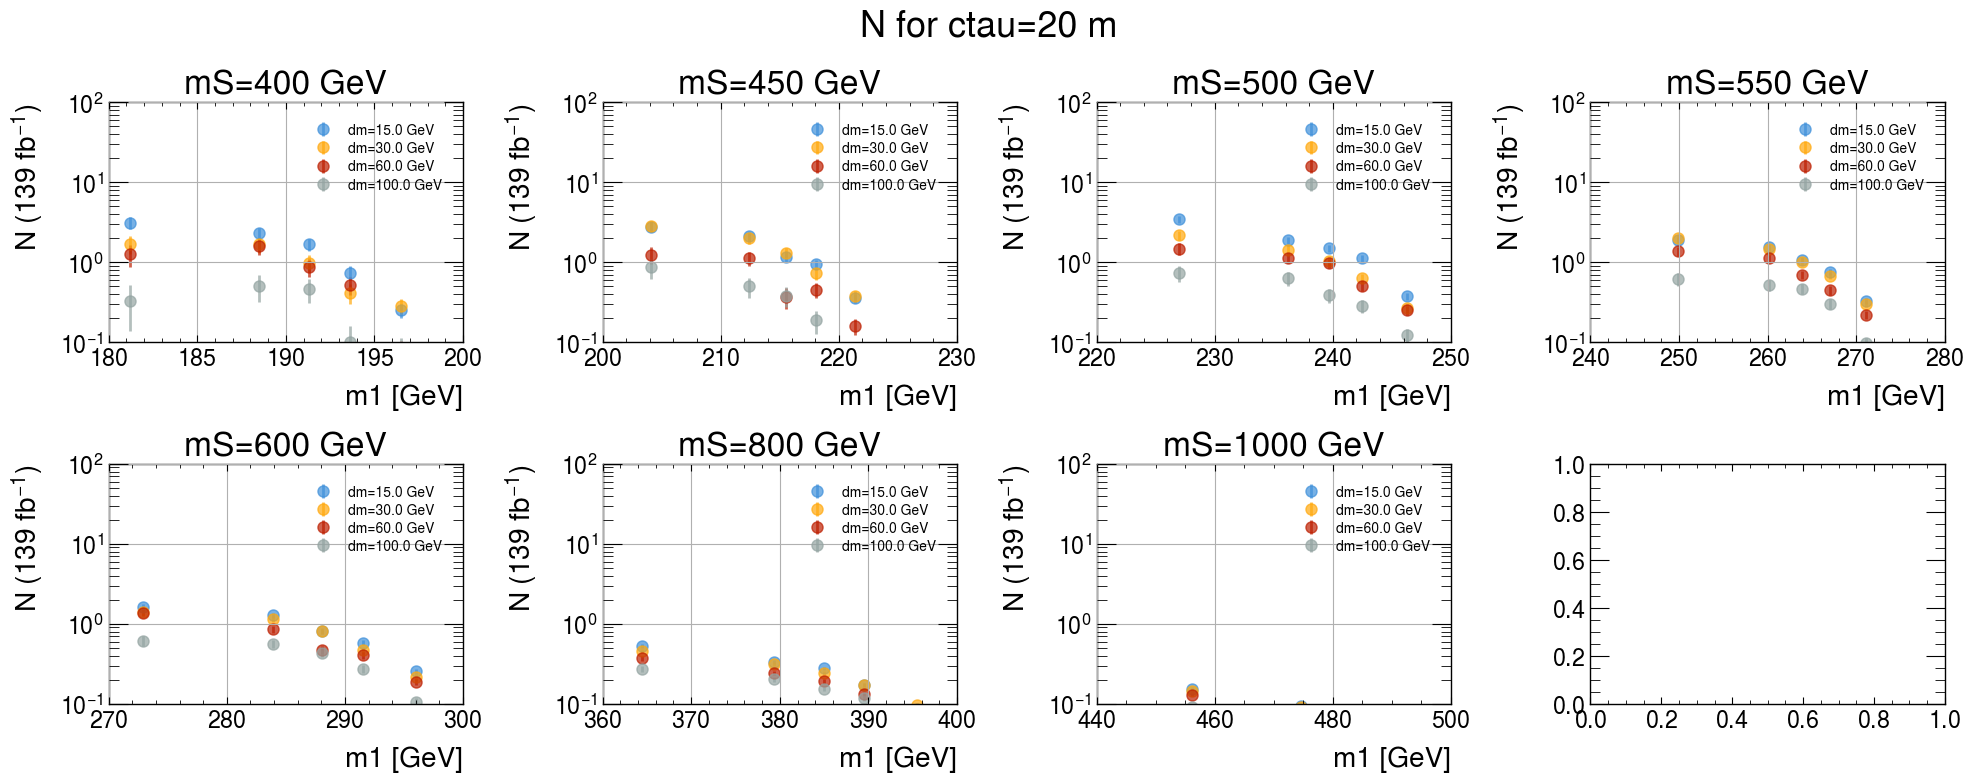

In [12]:
ncolumns = 4
mSValues = sorted(b2tf_DF['ms'].unique())
nrows = len(mSValues) // ncolumns + (len(mSValues) % ncolumns > 0)
ctau = 20.0
fig,axarr = plt.subplots(nrows=nrows, ncols=ncolumns, figsize=(5*ncolumns, 4*nrows))
iax = 0
axes = axarr.flatten() if nrows > 1 else [axarr]
for ms in mSValues:
    df = b2tf_DF[(b2tf_DF['ms'] == ms) & (b2tf_DF['ctau'].round(0) == ctau)].sort_values(by=['dm', 'm1'])
    alpha=0.7
    for dm,dfB in df.groupby('dm'):        
        axes[iax].errorbar(dfB['m1'], dfB['N_Run2'], 
                            yerr=dfB['N_Run2_err'], fmt='o', label=f'dm={dm:.1f} GeV', alpha=alpha)
        # alpha -= 0.2
        
    axes[iax].set_xlabel('m1 [GeV]')
    axes[iax].set_ylabel(r'N (139 fb$^{-1}$)')
    axes[iax].legend(fontsize=10)
    axes[iax].set_title(f'mS={ms:.0f} GeV')
    axes[iax].set_yscale('log')
    axes[iax].set_ylim(1e-1, 1e2)
    axes[iax].grid()
    iax += 1
plt.suptitle(f'N for ctau={ctau:.0f} m', fontsize=26)
plt.tight_layout()
plt.show()